<a href="https://colab.research.google.com/github/JOHN9903/infusion-pump-maintenance-analytics/blob/main/Infusion_Pump_Failure_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# STEP 1: Import the libraries we need

import numpy as np
import pandas as pd

# STEP 2: Make results reproducible
# Running this cell again produces the same synthetic dataset.
np.random.seed(42)

# STEP 3: Generate fictional infusion pump information
n = 1500

age_years = np.random.uniform(0.5, 10, n)
monthly_hours = np.random.randint(40, 301, n)
previous_faults = np.random.poisson(1.2, n)
battery_pct = np.random.uniform(35, 100, n)
months_since_service = np.random.randint(0, 19, n)

# STEP 4: Create illustrative failure probabilities.
# These rules are invented for demonstration, not derived
# from actual infusion pump failure data.

risk_score = (
    -3.5
    + 0.18 * age_years
    + 0.004 * monthly_hours
    + 0.35 * previous_faults
    - 0.025 * battery_pct
    + 0.07 * months_since_service
)

# Convert the score to a probability between 0 and 1.
probability = 1 / (1 + np.exp(-risk_score))

# STEP 5: Generate a fictional failure outcome.
failed_next_30_days = np.random.binomial(1, probability)

# STEP 6: Build the dataset.
df = pd.DataFrame({
    "age_years": age_years.round(1),
    "monthly_hours": monthly_hours,
    "previous_faults_90d": previous_faults,
    "battery_capacity_pct": battery_pct.round(1),
    "months_since_service": months_since_service,
    "failed_next_30_days": failed_next_30_days
})

# STEP 7: Display the results.
print("Dataset created successfully!")
print("Dataset size:", df.shape)
display(df.head(10))


Dataset created successfully!
Dataset size: (1500, 6)


,age_years,monthly_hours,previous_faults_90d,battery_capacity_pct,months_since_service,failed_next_30_days
0,4.1,156,2,86.9,17,0
1,9.5,260,2,81.0,18,0
2,7.5,193,2,47.4,0,0
3,6.2,192,0,58.8,7,0
4,2.0,51,2,41.9,15,0
5,2.0,172,0,75.8,1,0
6,1.1,267,1,42.9,7,0
7,8.7,82,2,99.1,5,0
8,6.2,60,0,85.7,15,0
9,7.2,146,4,60.4,10,0


In [2]:

# Check the size of the dataset
print("Rows and columns:", df.shape)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count failures and non-failures
print("\nFailure outcome counts:")
print(df["failed_next_30_days"].value_counts())

# Calculate the percentage of failures
print("\nOutcome percentages:")
print(
    df["failed_next_30_days"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# View basic statistics
print("\nDataset summary:")
display(df.describe().round(2))


Rows and columns: (1500, 6)

Missing values:
age_years               0
monthly_hours           0
previous_faults_90d     0
battery_capacity_pct    0
months_since_service    0
failed_next_30_days     0
dtype: int64

Failure outcome counts:
failed_next_30_days
0    1349
1     151
Name: count, dtype: int64

Outcome percentages:
failed_next_30_days
0    89.93
1    10.07
Name: proportion, dtype: float64

Dataset summary:


,age_years,monthly_hours,previous_faults_90d,battery_capacity_pct,months_since_service,failed_next_30_days
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.0
mean,5.24,168.83,1.17,67.20,9.18,0.1
std,2.79,73.63,1.06,18.58,5.42,0.3
min,0.50,40.00,0.00,35.00,0.00,0.0
25%,2.80,106.00,0.00,51.30,5.00,0.0
50%,5.30,168.50,1.00,67.00,9.00,0.0
75%,7.70,229.00,2.00,83.22,14.00,0.0
max,10.00,300.00,5.00,99.90,18.00,1.0


In [3]:

# Check the size of the dataset
print("Rows and columns:", df.shape)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count failures and non-failures
print("\nFailure outcome counts:")
print(df["failed_next_30_days"].value_counts())

# Calculate the percentage of failures
print("\nOutcome percentages:")
print(
    df["failed_next_30_days"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# View basic statistics
print("\nDataset summary:")
display(df.describe().round(2))


Rows and columns: (1500, 6)

Missing values:
age_years               0
monthly_hours           0
previous_faults_90d     0
battery_capacity_pct    0
months_since_service    0
failed_next_30_days     0
dtype: int64

Failure outcome counts:
failed_next_30_days
0    1349
1     151
Name: count, dtype: int64

Outcome percentages:
failed_next_30_days
0    89.93
1    10.07
Name: proportion, dtype: float64

Dataset summary:


,age_years,monthly_hours,previous_faults_90d,battery_capacity_pct,months_since_service,failed_next_30_days
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.0
mean,5.24,168.83,1.17,67.20,9.18,0.1
std,2.79,73.63,1.06,18.58,5.42,0.3
min,0.50,40.00,0.00,35.00,0.00,0.0
25%,2.80,106.00,0.00,51.30,5.00,0.0
50%,5.30,168.50,1.00,67.00,9.00,0.0
75%,7.70,229.00,2.00,83.22,14.00,0.0
max,10.00,300.00,5.00,99.90,18.00,1.0


No failure (0): 1349
Failure (1): 151
Total observations: 1500


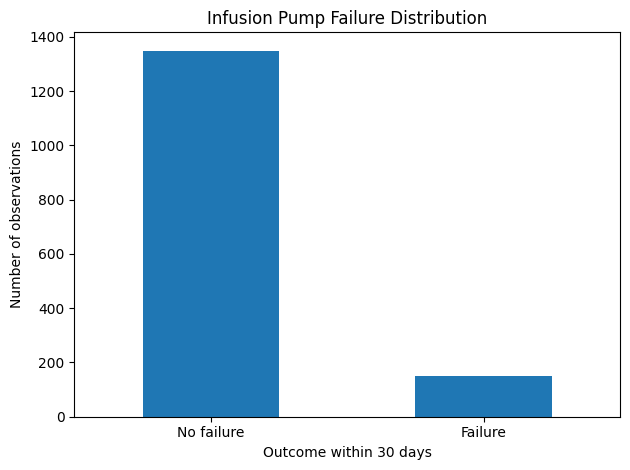

In [4]:

import matplotlib.pyplot as plt

# Count the two possible outcomes
failure_counts = df["failed_next_30_days"].value_counts().reindex(
    [0, 1], fill_value=0
)

print("No failure (0):", failure_counts[0])
print("Failure (1):", failure_counts[1])
print("Total observations:", len(df))

# Visualize the distribution
failure_counts.rename({
    0: "No failure",
    1: "Failure"
}).plot(kind="bar", rot=0)

plt.title("Infusion Pump Failure Distribution")
plt.xlabel("Outcome within 30 days")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()


In [5]:

# Check data types, non-null values and column names
df.info()

# Count missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check the range of each variable
print("\nMinimum and maximum values:")
display(df.describe().loc[["min", "max"]].T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_years             1500 non-null   float64
 1   monthly_hours         1500 non-null   int64  
 2   previous_faults_90d   1500 non-null   int64  
 3   battery_capacity_pct  1500 non-null   float64
 4   months_since_service  1500 non-null   int64  
 5   failed_next_30_days   1500 non-null   int64  
dtypes: float64(2), int64(4)
memory usage: 70.4 KB

Missing values per column:
age_years               0
monthly_hours           0
previous_faults_90d     0
battery_capacity_pct    0
months_since_service    0
failed_next_30_days     0
dtype: int64

Duplicate rows: 0

Minimum and maximum values:


,min,max
age_years,0.5,10.0
monthly_hours,40.0,300.0
previous_faults_90d,0.0,5.0
battery_capacity_pct,35.0,99.9
months_since_service,0.0,18.0
failed_next_30_days,0.0,1.0


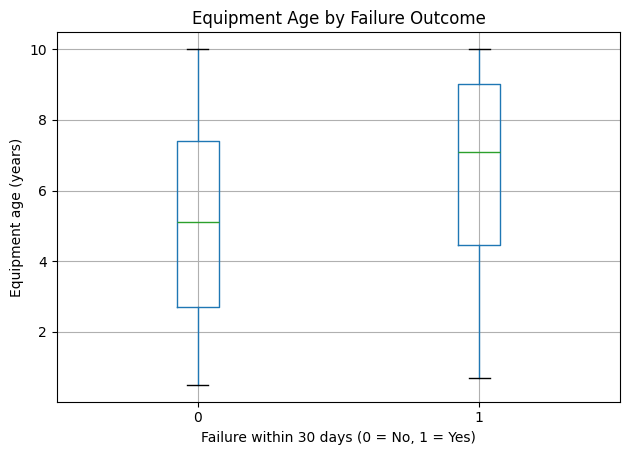

In [6]:

# Compare equipment age for the two outcome groups
df.boxplot(
    column="age_years",
    by="failed_next_30_days"
)

plt.title("Equipment Age by Failure Outcome")
plt.suptitle("")
plt.xlabel("Failure within 30 days (0 = No, 1 = Yes)")
plt.ylabel("Equipment age (years)")
plt.tight_layout()
plt.show()


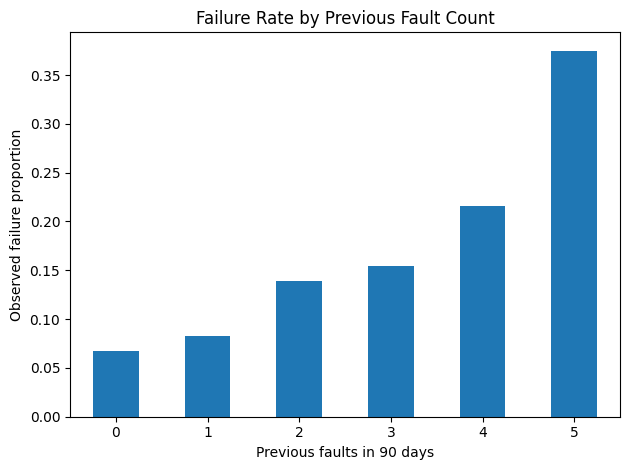

In [7]:

# Calculate the observed failure rate for each fault count
fault_rates = df.groupby(
    "previous_faults_90d"
)["failed_next_30_days"].mean()

fault_rates.plot(kind="bar", rot=0)

plt.title("Failure Rate by Previous Fault Count")
plt.xlabel("Previous faults in 90 days")
plt.ylabel("Observed failure proportion")
plt.tight_layout()
plt.show()


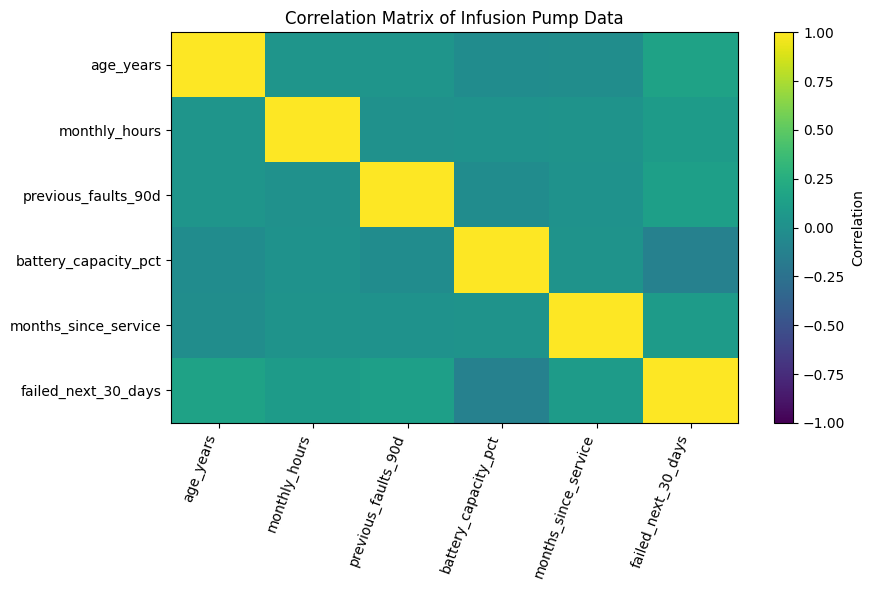

Correlation with failure outcome:


,correlation
age_years,0.152623
previous_faults_90d,0.130110
monthly_hours,0.095836
months_since_service,0.094614
battery_capacity_pct,-0.118157


In [8]:

# Correlation matrix
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(9, 6))
plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=70,
    ha="right"
)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Matrix of Infusion Pump Data")
plt.tight_layout()
plt.show()

# Print correlations with the target
print("Correlation with failure outcome:")
display(
    correlation["failed_next_30_days"]
    .drop("failed_next_30_days")
    .sort_values(ascending=False)
    .to_frame("correlation")
)


In [9]:

# Select the information the model will use
features = [
    "age_years",
    "monthly_hours",
    "previous_faults_90d",
    "battery_capacity_pct",
    "months_since_service"
]

X = df[features]

# Select the outcome we want to predict
y = df["failed_next_30_days"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Feature dataset shape: (1500, 5)
Target dataset shape: (1500,)

Feature columns:
['age_years', 'monthly_hours', 'previous_faults_90d', 'battery_capacity_pct', 'months_since_service']

Target distribution:
failed_next_30_days
0    1349
1     151
Name: count, dtype: int64


In [10]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature rows:", len(X_train))
print("Testing feature rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training feature rows: 1200
Testing feature rows: 300

Training target distribution:
failed_next_30_days
0    0.899
1    0.101
Name: proportion, dtype: float64

Testing target distribution:
failed_next_30_days
0    0.9
1    0.1
Name: proportion, dtype: float64


In [11]:
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert list(X_train.columns) == features
assert "failed_next_30_days" not in X_train.columns
assert set(y.unique()).issubset({0, 1})

print("SUCCESS: Data is ready for machine learning!")

SUCCESS: Data is ready for machine learning!


In [12]:

# STEP 1: Import the machine learning tools

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# STEP 2: Create the baseline model
# Scaling helps Logistic Regression work with variables
# measured in different units.

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# STEP 3: Create the Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# STEP 4: Train both models using training data only

baseline_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Logistic Regression training complete!")
print("Random Forest training complete!")


Logistic Regression training complete!
Random Forest training complete!


In [13]:

# Predict the outcome for each test observation

baseline_predictions = baseline_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Estimate failure probabilities
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Compare the first 10 predictions
comparison = X_test.head(10).copy()

comparison["Actual outcome"] = y_test.loc[X_test.head(10).index]
comparison["Logistic prediction"] = baseline_predictions[:10]
comparison["Random Forest prediction"] = rf_predictions[:10]
comparison["RF failure probability (%)"] = (
    rf_probabilities[:10] * 100
).round(1)

display(comparison)


,age_years,monthly_hours,previous_faults_90d,battery_capacity_pct,months_since_service,Actual outcome,Logistic prediction,Random Forest prediction,RF failure probability (%)
1459,6.8,267,1,38.5,10,0,1,0,42.9
1479,4.6,162,0,53.0,12,0,0,0,14.8
1288,0.8,44,0,74.4,5,0,0,0,14.2
1125,5.7,196,0,52.4,1,0,0,0,20.9
967,3.3,47,3,59.7,14,0,0,0,17.7
1256,2.4,118,0,78.4,13,0,0,0,7.9
913,4.4,103,2,45.5,11,1,1,0,24.9
327,6.3,88,2,67.7,8,0,0,0,20.5
944,2.5,263,2,81.2,0,0,0,0,5.1
1300,0.8,125,0,59.0,12,0,0,0,32.9


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.670,0.189,0.700,0.298,0.705
1,Random Forest,0.837,0.172,0.167,0.169,0.614


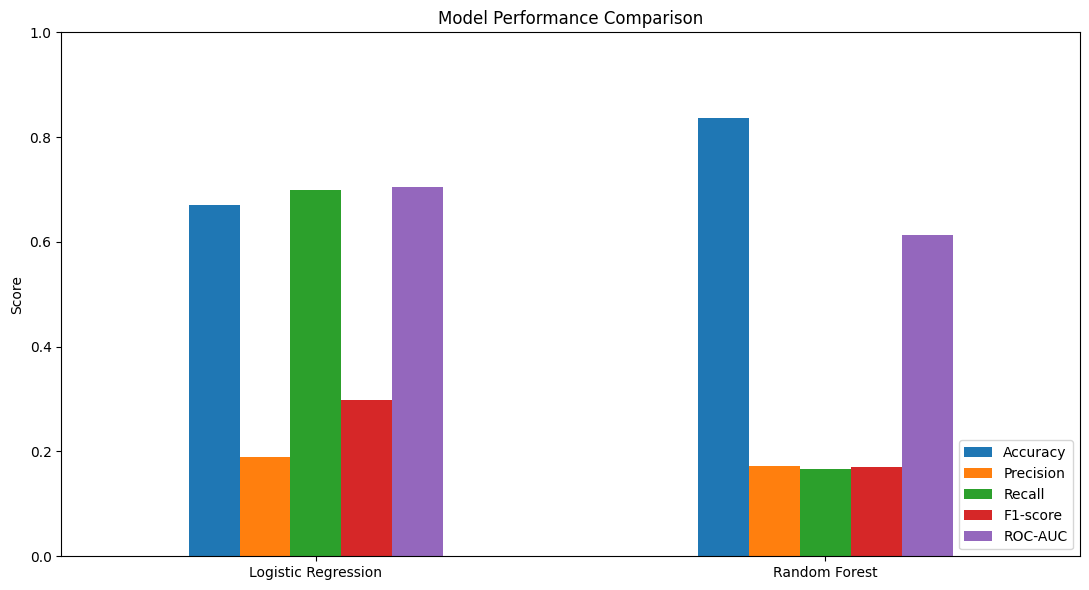

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, baseline_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

display(results.round(3))

results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

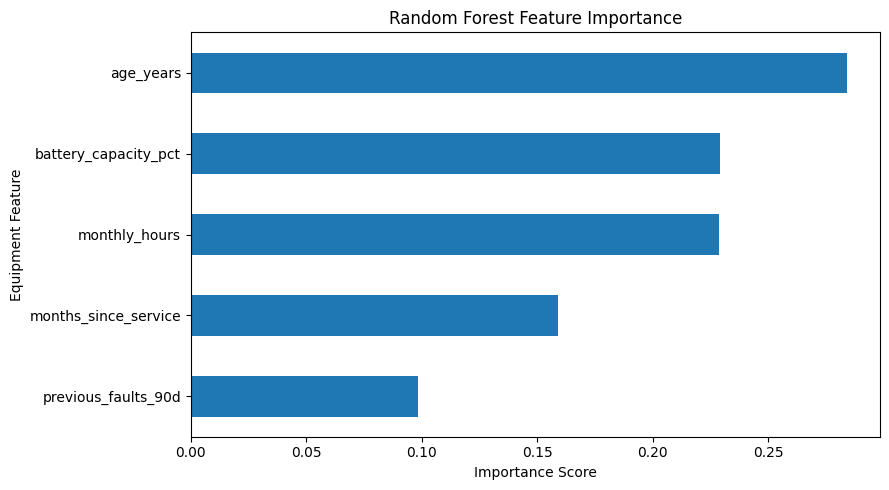

Feature importance ranking:


,Importance
age_years,0.284
battery_capacity_pct,0.229
monthly_hours,0.229
months_since_service,0.159
previous_faults_90d,0.098


In [18]:

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(9, 5))

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Equipment Feature")
plt.tight_layout()
plt.show()

print("Feature importance ranking:")
display(
    importance.sort_values(ascending=False).to_frame(
        "Importance"
    ).round(3)
)


,Threshold,Precision,Recall,Alerts
0,0.2,0.141,0.700,149
1,0.3,0.129,0.367,85
2,0.4,0.140,0.233,50
3,0.5,0.172,0.167,29
4,0.6,0.273,0.100,11
5,0.7,0.667,0.067,3


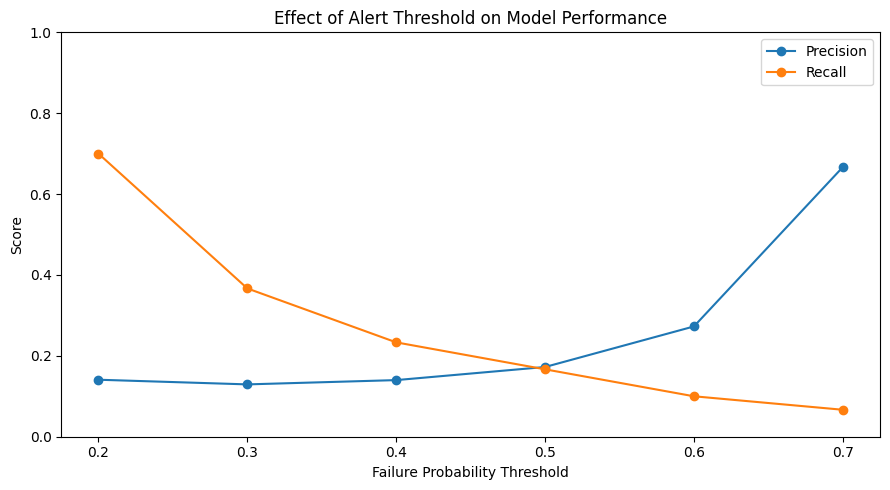

In [19]:

from sklearn.metrics import precision_score, recall_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:
    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Alerts": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

threshold_df.set_index("Threshold")[
    ["Precision", "Recall"]
].plot(marker="o", figsize=(9, 5))

plt.title("Effect of Alert Threshold on Model Performance")
plt.xlabel("Failure Probability Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [20]:

import joblib

joblib.dump(rf_model, "infusion_pump_rf_model.joblib")

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [21]:
from google.colab import files

files.download("infusion_pump_rf_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from sklearn.metrics import confusion_matrix

print("MODEL COMPARISON")
display(results.round(3))

print("\nRANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test, rf_predictions))

print("\nRANDOM FOREST FEATURE IMPORTANCE")
display(
    pd.Series(
        rf_model.feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=False).round(3)
)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.670,0.189,0.700,0.298,0.705
1,Random Forest,0.837,0.172,0.167,0.169,0.614



RANDOM FOREST CONFUSION MATRIX
[[246  24]
 [ 25   5]]

RANDOM FOREST FEATURE IMPORTANCE


,0
age_years,0.284
battery_capacity_pct,0.229
monthly_hours,0.229
months_since_service,0.159
previous_faults_90d,0.098


In [24]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

rows = []

for threshold in thresholds:
    for name, probabilities in [
        ("Logistic Regression", baseline_probabilities),
        ("Random Forest", rf_probabilities)
    ]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Alerts": int(predictions.sum()),
            "Missed failures": int(fn)
        })

threshold_results = pd.DataFrame(rows)

display(
    threshold_results.round(3).sort_values(
        ["Model", "Threshold"]
    )
)


,Model,Threshold,Precision,Recall,F1-score,Alerts,Missed failures
0,Logistic Regression,0.2,0.114,0.967,0.204,254,1
2,Logistic Regression,0.3,0.137,0.933,0.238,205,2
4,Logistic Regression,0.4,0.157,0.800,0.262,153,6
6,Logistic Regression,0.5,0.189,0.700,0.298,111,9
8,Logistic Regression,0.6,0.196,0.333,0.247,51,20
10,Logistic Regression,0.7,0.273,0.200,0.231,22,24
1,Random Forest,0.2,0.141,0.700,0.235,149,9
3,Random Forest,0.3,0.129,0.367,0.191,85,19
5,Random Forest,0.4,0.140,0.233,0.175,50,23
7,Random Forest,0.5,0.172,0.167,0.169,29,25


In [25]:

from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Model training rows:", len(X_subtrain))
print("Validation rows:", len(X_val))
print("Final test rows:", len(X_test))
print("\nFailures in validation set:", int(y_val.sum()))


Model training rows: 900
Validation rows: 300
Final test rows: 300

Failures in validation set: 30


In [26]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Logistic Regression
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# Train using only the subtraining data
baseline_model.fit(X_subtrain, y_subtrain)
rf_model.fit(X_subtrain, y_subtrain)

print("Both models retrained successfully!")


Both models retrained successfully!


In [27]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Predictions on validation data only
lr_val_probs = baseline_model.predict_proba(X_val)[:, 1]
rf_val_probs = rf_model.predict_proba(X_val)[:, 1]

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30,
              0.35, 0.40, 0.50, 0.60, 0.70]

rows = []

for threshold in thresholds:
    for name, probabilities in [
        ("Logistic Regression", lr_val_probs),
        ("Random Forest", rf_val_probs)
    ]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "Alerts": int(predictions.sum()),
            "False alarms": int(fp),
            "Missed failures": int(fn)
        })

validation_results = pd.DataFrame(rows)

display(
    validation_results.round(3).sort_values(
        ["Model", "Threshold"]
    ).reset_index(drop=True)
)


,Model,Threshold,Precision,Recall,F1-score,Alerts,False alarms,Missed failures
0,Logistic Regression,0.10,0.101,1.000,0.183,298,268,0
1,Logistic Regression,0.15,0.107,1.000,0.194,280,250,0
2,Logistic Regression,0.20,0.109,0.967,0.195,267,238,1
3,Logistic Regression,0.25,0.119,0.967,0.212,243,214,1
4,Logistic Regression,0.30,0.130,0.933,0.229,215,187,2
5,Logistic Regression,0.35,0.143,0.867,0.245,182,156,4
6,Logistic Regression,0.40,0.156,0.833,0.263,160,135,5
7,Logistic Regression,0.50,0.210,0.700,0.323,100,79,9
8,Logistic Regression,0.60,0.233,0.567,0.330,73,56,13
9,Logistic Regression,0.70,0.289,0.367,0.324,38,27,19


In [28]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Selected model and threshold from validation
selected_model = baseline_model
selected_threshold = 0.30

# Predict probabilities on the untouched test set
test_probabilities = selected_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Calculate final test metrics
tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

final_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Threshold": selected_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "True positives": tp,
    "False positives": fp,
    "True negatives": tn,
    "Missed failures": fn,
    "Total alerts": int(test_predictions.sum())
}])

display(final_results.round(3))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No failure", "Failure"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))


,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,True positives,False positives,True negatives,Missed failures,Total alerts
0,Logistic Regression,0.3,0.38,0.132,0.933,0.231,0.701,28,184,86,2,212



Classification report:
              precision    recall  f1-score   support

  No failure       0.98      0.32      0.48       270
     Failure       0.13      0.93      0.23        30

    accuracy                           0.38       300
   macro avg       0.55      0.63      0.36       300
weighted avg       0.89      0.38      0.46       300


Confusion matrix:
[[ 86 184]
 [  2  28]]


In [29]:

!pip -q install gradio


In [30]:

import gradio as gr
import pandas as pd

# Threshold selected using validation data
DASHBOARD_THRESHOLD = 0.30

def predict_pump_failure(
    age_years,
    monthly_hours,
    previous_faults_90d,
    battery_capacity_pct,
    months_since_service
):
    # Arrange inputs in exactly the feature order used for training
    pump_data = pd.DataFrame([{
        "age_years": age_years,
        "monthly_hours": monthly_hours,
        "previous_faults_90d": previous_faults_90d,
        "battery_capacity_pct": battery_capacity_pct,
        "months_since_service": months_since_service
    }])

    # Estimate failure probability
    probability = baseline_model.predict_proba(
        pump_data
    )[0, 1]

    # Apply the selected classification threshold
    if probability >= DASHBOARD_THRESHOLD:
        alert = "⚠️ PREDICTED FAILURE RISK ALERT"
        recommendation = (
            "For demonstration only: flag this simulated pump "
            "for review by qualified maintenance personnel."
        )
    else:
        alert = "✅ BELOW THE SELECTED ALERT THRESHOLD"
        recommendation = (
            "For demonstration only: the model did not raise "
            "an alert. This does not establish that the pump is safe."
        )

    return (
        alert,
        f"{probability:.1%}",
        f"Selected threshold: {DASHBOARD_THRESHOLD:.0%}",
        recommendation
    )

with gr.Blocks(title="Infusion Pump Predictive Maintenance") as dashboard:
    gr.Markdown(
        """
        # Infusion Pump Predictive Maintenance
        ### Machine Learning Prototype

        Enter simulated pump measurements to explore the model.
        This demonstration uses synthetic data and is not validated
        for clinical or real equipment-safety decisions.
        """
    )

    with gr.Row():
        age = gr.Slider(
            minimum=0.5, maximum=10, value=5,
            step=0.1, label="Pump age (years)"
        )
        hours = gr.Slider(
            minimum=40, maximum=300, value=150,
            step=1, label="Operating hours per month"
        )

    with gr.Row():
        faults = gr.Slider(
            minimum=0, maximum=10, value=1,
            step=1, label="Previous faults in 90 days"
        )
        battery = gr.Slider(
            minimum=35, maximum=100, value=80,
            step=0.5, label="Battery capacity (%)"
        )

    service = gr.Slider(
        minimum=0, maximum=18, value=6,
        step=1, label="Months since last service"
    )

    predict_button = gr.Button(
        "Predict Failure Risk",
        variant="primary"
    )

    alert_output = gr.Textbox(label="Model alert")
    probability_output = gr.Textbox(
        label="Estimated failure probability"
    )
    threshold_output = gr.Textbox(label="Decision threshold")
    recommendation_output = gr.Textbox(
        label="Prototype interpretation"
    )

    predict_button.click(
        fn=predict_pump_failure,
        inputs=[age, hours, faults, battery, service],
        outputs=[
            alert_output,
            probability_output,
            threshold_output,
            recommendation_output
        ]
    )

dashboard.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://47b1e3f1a699b02d82.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [31]:

import numpy as np
import pandas as pd

np.random.seed(123)

n_pumps = 100

pump_inventory = pd.DataFrame({
    "pump_id": [f"IP-{i:03d}" for i in range(1, n_pumps + 1)],
    "age_years": np.round(np.random.uniform(0.5, 10, n_pumps), 1),
    "monthly_hours": np.random.randint(40, 301, n_pumps),
    "previous_faults_90d": np.random.poisson(1.2, n_pumps),
    "battery_capacity_pct": np.round(
        np.random.uniform(35, 100, n_pumps), 1
    ),
    "months_since_service": np.random.randint(0, 19, n_pumps)
})

print("Simulated hospital pump inventory created!")
print("Number of pumps:", len(pump_inventory))
display(pump_inventory.head(10))


Simulated hospital pump inventory created!
Number of pumps: 100


,pump_id,age_years,monthly_hours,previous_faults_90d,battery_capacity_pct,months_since_service
0,IP-001,7.1,117,1,37.4,14
1,IP-002,3.2,48,1,37.6,16
2,IP-003,2.7,246,2,56.6,3
3,IP-004,5.7,105,1,96.6,3
4,IP-005,7.3,262,3,75.1,14
5,IP-006,4.5,238,0,59.0,11
6,IP-007,9.8,80,2,74.8,6
7,IP-008,7.0,116,2,48.4,3
8,IP-009,5.1,193,2,45.7,5
9,IP-010,4.2,163,0,58.5,15


In [32]:

import gradio as gr
import pandas as pd
import tempfile
import os

# Confirm that the previously trained model is available
if "baseline_model" not in globals():
    raise NameError(
        "Please run your model-training cells before launching this dashboard."
    )

FEATURE_COLUMNS = [
    "age_years",
    "monthly_hours",
    "previous_faults_90d",
    "battery_capacity_pct",
    "months_since_service"
]

def analyze_inventory(threshold):
    # Copy the fictional inventory
    results = pump_inventory.copy()

    # Estimate probability for every pump
    results["failure_probability_pct"] = (
        baseline_model.predict_proba(
            results[FEATURE_COLUMNS]
        )[:, 1] * 100
    ).round(1)

    # Flag pumps based on the selected threshold
    results["alert"] = (
        results["failure_probability_pct"] >= threshold * 100
    ).map({
        True: "REVIEW FLAG",
        False: "Below threshold"
    })

    # Rank by estimated probability
    results = results.sort_values(
        "failure_probability_pct",
        ascending=False
    ).reset_index(drop=True)

    results.insert(0, "risk_rank", range(1, len(results) + 1))

    # Summary
    total = len(results)
    alerts = int((results["alert"] == "REVIEW FLAG").sum())
    highest_risk = results.iloc[0]

    summary = (
        f"Simulated pumps: {total}\n"
        f"Review flags: {alerts}\n"
        f"Below threshold: {total - alerts}\n"
        f"Highest estimated risk: {highest_risk['pump_id']} "
        f"({highest_risk['failure_probability_pct']:.1f}%)\n\n"
        "Research demonstration only. A review flag is not proof "
        "that a pump will fail or that an unflagged pump is safe."
    )

    # Save a CSV report for download
    report = tempfile.NamedTemporaryFile(
        mode="w",
        suffix=".csv",
        prefix="infusion_pump_predictions_",
        delete=False,
        encoding="utf-8"
    )
    report_path = report.name
    report.close()

    results.to_csv(report_path, index=False)

    return results, summary, report_path


with gr.Blocks(
    title="Hospital Infusion Pump Maintenance Dashboard"
) as multi_pump_dashboard:

    gr.Markdown(
        """
        # Hospital Infusion Pump Predictive Maintenance
        ### Multi-Pump Research Prototype

        Review and rank a simulated inventory of infusion pumps.
        All records are fictional and model outputs are not validated
        for real equipment-safety decisions.
        """
    )

    threshold_slider = gr.Slider(
        minimum=0.05,
        maximum=0.80,
        value=0.30,
        step=0.05,
        label="Alert threshold"
    )

    analyze_button = gr.Button(
        "Analyze Pump Inventory",
        variant="primary"
    )

    summary_output = gr.Textbox(
        label="Inventory Overview",
        lines=6
    )

    inventory_output = gr.Dataframe(
        label="Pumps Ranked by Estimated Failure Probability",
        interactive=False
    )

    download_output = gr.File(
        label="Download Prediction Report (CSV)"
    )

    analyze_button.click(
        fn=analyze_inventory,
        inputs=[threshold_slider],
        outputs=[
            inventory_output,
            summary_output,
            download_output
        ]
    )

    # Display initial results immediately
    multi_pump_dashboard.load(
        fn=analyze_inventory,
        inputs=[threshold_slider],
        outputs=[
            inventory_output,
            summary_output,
            download_output
        ]
    )

multi_pump_dashboard.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b97e83e325f3bb625c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://47b1e3f1a699b02d82.gradio.live
Killing tunnel 127.0.0.1:7861 <> https://b97e83e325f3bb625c.gradio.live


In [33]:
!pip -q install plotly

In [34]:

import gradio as gr
import pandas as pd
import plotly.express as px
import tempfile

FEATURE_COLUMNS = [
    "age_years",
    "monthly_hours",
    "previous_faults_90d",
    "battery_capacity_pct",
    "months_since_service"
]

def visual_dashboard(threshold, view):
    results = pump_inventory.copy()

    results["failure_probability_pct"] = (
        baseline_model.predict_proba(
            results[FEATURE_COLUMNS]
        )[:, 1] * 100
    ).round(1)

    results["alert"] = results[
        "failure_probability_pct"
    ].ge(threshold * 100).map({
        True: "Review flag",
        False: "Below threshold"
    })

    results = results.sort_values(
        "failure_probability_pct",
        ascending=False
    ).reset_index(drop=True)

    results.insert(0, "risk_rank", range(1, len(results) + 1))

    if view == "Flagged pumps only":
        displayed = results[
            results["alert"] == "Review flag"
        ].copy()
    else:
        displayed = results.copy()

    total = len(results)
    flagged = int((results["alert"] == "Review flag").sum())
    average_risk = results["failure_probability_pct"].mean()

    summary = (
        f"Total simulated pumps: {total}\n"
        f"Review flags: {flagged}\n"
        f"Below threshold: {total - flagged}\n"
        f"Average estimated probability: {average_risk:.1f}%\n"
        f"Current threshold: {threshold:.0%}\n\n"
        "Synthetic-data research demonstration only. "
        "Scores are not validated predictions of real pump failures."
    )

    top10 = results.head(10).sort_values(
        "failure_probability_pct"
    )

    bar_chart = px.bar(
        top10,
        x="failure_probability_pct",
        y="pump_id",
        orientation="h",
        title="10 Highest Estimated Failure Probabilities",
        labels={
            "failure_probability_pct": "Estimated probability (%)",
            "pump_id": "Pump"
        }
    )
    bar_chart.update_layout(
        xaxis_range=[0, 100],
        height=430
    )

    risk_chart = px.histogram(
        results,
        x="failure_probability_pct",
        nbins=10,
        title="Distribution of Estimated Risk",
        labels={
            "failure_probability_pct": "Estimated probability (%)",
            "count": "Number of pumps"
        }
    )
    risk_chart.add_vline(
        x=threshold * 100,
        line_dash="dash",
        annotation_text="Selected threshold"
    )
    risk_chart.update_layout(height=350)

    report = tempfile.NamedTemporaryFile(
        mode="w",
        suffix=".csv",
        prefix="pump_risk_report_",
        delete=False,
        encoding="utf-8"
    )
    report.close()
    displayed.to_csv(report.name, index=False)

    return summary, displayed, bar_chart, risk_chart, report.name


with gr.Blocks(
    title="Infusion Pump Analytics"
) as analytics_app:

    gr.Markdown(
        """
        # Infusion Pump Maintenance Analytics
        **Multi-pump machine learning research prototype**

        All records are simulated. Model outputs are not validated
        for clinical or real equipment-safety decisions.
        """
    )

    threshold = gr.Slider(
        minimum=0.05,
        maximum=0.80,
        value=0.30,
        step=0.05,
        label="Review threshold"
    )

    view = gr.Radio(
        choices=["All pumps", "Flagged pumps only"],
        value="All pumps",
        label="Inventory filter"
    )

    run_button = gr.Button(
        "Refresh Analytics",
        variant="primary"
    )

    summary = gr.Textbox(
        label="Inventory Summary",
        lines=6
    )

    table = gr.Dataframe(
        label="Ranked Pump Inventory",
        interactive=False
    )

    bar = gr.Plot(label="Highest-Risk Pumps")
    histogram = gr.Plot(label="Risk Distribution")

    download = gr.File(label="Download CSV Report")

    run_button.click(
        fn=visual_dashboard,
        inputs=[threshold, view],
        outputs=[summary, table, bar, histogram, download]
    )

    analytics_app.load(
        fn=visual_dashboard,
        inputs=[threshold, view],
        outputs=[summary, table, bar, histogram, download]
    )

analytics_app.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f0309dd38b68a1243d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://f0309dd38b68a1243d.gradio.live


In [35]:

import gradio as gr
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import tempfile
import os

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

FEATURE_COLUMNS = [
    "age_years",
    "monthly_hours",
    "previous_faults_90d",
    "battery_capacity_pct",
    "months_since_service"
]

DEFAULT_THRESHOLD = 0.30

# Confirm the required objects already exist
required_objects = ["pump_inventory", "baseline_model"]

for obj in required_objects:
    if obj not in globals():
        raise NameError(
            f"{obj} is missing. Run the earlier inventory "
            "and model-training cells first."
        )

# Work with a copy so the original inventory stays unchanged
inventory = pump_inventory.copy()

# Ensure all required columns exist
required_columns = ["pump_id"] + FEATURE_COLUMNS
missing_columns = [
    col for col in required_columns if col not in inventory.columns
]

if missing_columns:
    raise ValueError(f"Missing inventory columns: {missing_columns}")


# --------------------------------------------------
# 2. SINGLE-PUMP INVESTIGATION FUNCTION
# --------------------------------------------------

def investigate_pump(pump_id, threshold):

    if not pump_id:
        return (
            "Select a pump to begin.",
            pd.DataFrame(),
            go.Figure(),
            pd.DataFrame(),
            None
        )

    # Calculate scores for the entire inventory
    all_probabilities = baseline_model.predict_proba(
        inventory[FEATURE_COLUMNS]
    )[:, 1]

    ranked_inventory = inventory.copy()
    ranked_inventory["estimated_risk"] = all_probabilities
    ranked_inventory["status"] = np.where(
        ranked_inventory["estimated_risk"] >= threshold,
        "Flag for review",
        "Below threshold"
    )

    ranked_inventory = ranked_inventory.sort_values(
        "estimated_risk", ascending=False
    ).reset_index(drop=True)

    # Find the selected pump
    selected_rows = ranked_inventory[
        ranked_inventory["pump_id"] == pump_id
    ]

    if selected_rows.empty:
        raise ValueError("The selected pump was not found.")

    pump = selected_rows.iloc[0]
    probability = float(pump["estimated_risk"])
    rank = int(
        ranked_inventory.index[
            ranked_inventory["pump_id"] == pump_id
        ][0]
    ) + 1

    status = (
        "⚠️ FLAGGED FOR MAINTENANCE REVIEW"
        if probability >= threshold
        else "✅ BELOW THE SELECTED REVIEW THRESHOLD"
    )

    # --------------------------------------------------
    # 3. SUMMARY
    # --------------------------------------------------

    summary = f"""
## Pump investigation: {pump_id}

### {status}

- **Estimated failure probability:** {probability:.1%}
- **Selected review threshold:** {threshold:.0%}
- **Risk ranking:** #{rank} of {len(ranked_inventory)} simulated pumps
- **Pumps at or above threshold:** {
        int((ranked_inventory["estimated_risk"] >= threshold).sum())
    } of {len(ranked_inventory)}

**Important:** This score comes from a model trained on synthetic data.
It is not a verified probability of real equipment failure.
"""

    # --------------------------------------------------
    # 4. TECHNICAL PROFILE
    # --------------------------------------------------

    feature_labels = {
        "age_years": "Pump age (years)",
        "monthly_hours": "Operating hours per month",
        "previous_faults_90d": "Previous faults (90 days)",
        "battery_capacity_pct": "Battery capacity (%)",
        "months_since_service": "Months since last service"
    }

    profile = pd.DataFrame({
        "Measurement": [
            feature_labels[col] for col in FEATURE_COLUMNS
        ],
        "Recorded value": [
            pump[col] for col in FEATURE_COLUMNS
        ]
    })

    # --------------------------------------------------
    # 5. RISK GAUGE
    # --------------------------------------------------

    gauge = go.Figure(
        go.Indicator(
            mode="gauge+number",
            value=probability * 100,
            number={"suffix": "%"},
            title={"text": "Model-estimated risk score"},
            gauge={
                "axis": {"range": [0, 100]},
                "bar": {"color": "#2563eb"},
                "steps": [
                    {"range": [0, threshold * 100],
                     "color": "#dbeafe"},
                    {"range": [threshold * 100, 100],
                     "color": "#fee2e2"}
                ],
                "threshold": {
                    "line": {"color": "#dc2626", "width": 4},
                    "thickness": 0.8,
                    "value": threshold * 100
                }
            }
        )
    )

    gauge.update_layout(
        height=320,
        margin=dict(l=25, r=25, t=65, b=20)
    )

    # --------------------------------------------------
    # 6. COMPARE WITH NEARBY-RANKED PUMPS
    # --------------------------------------------------

    start = max(0, rank - 3)
    end = min(len(ranked_inventory), rank + 2)

    comparison = ranked_inventory.iloc[start:end][
        ["pump_id", "estimated_risk", "status"]
    ].copy()

    comparison["estimated_risk"] = (
        comparison["estimated_risk"] * 100
    ).round(1)

    comparison = comparison.rename(columns={
        "pump_id": "Pump ID",
        "estimated_risk": "Estimated risk (%)",
        "status": "Review status"
    })

    # --------------------------------------------------
    # 7. CREATE INDIVIDUAL CSV REPORT
    # --------------------------------------------------

    report = pd.DataFrame([{
        "pump_id": pump_id,
        **{col: pump[col] for col in FEATURE_COLUMNS},
        "estimated_risk_probability": round(probability, 4),
        "selected_threshold": threshold,
        "risk_rank": rank,
        "inventory_size": len(ranked_inventory),
        "review_status": (
            "Flag for review"
            if probability >= threshold
            else "Below threshold"
        ),
        "data_type": "Simulated research data"
    }])

    with tempfile.NamedTemporaryFile(
        mode="w",
        suffix=".csv",
        prefix=f"{pump_id}_investigation_",
        delete=False,
        newline=""
    ) as temp_file:
        report.to_csv(temp_file.name, index=False)
        report_path = temp_file.name

    return summary, profile, gauge, comparison, report_path


# --------------------------------------------------
# 8. BUILD THE INVESTIGATION PAGE
# --------------------------------------------------

pump_ids = sorted(inventory["pump_id"].tolist())

with gr.Blocks(theme=gr.themes.Soft()) as investigation_app:

    gr.Markdown("""
    # Infusion Pump Investigation Centre

    **Predictive maintenance research prototype**

    Select an individual simulated pump to inspect its measurements,
    model score, risk ranking, and review status.
    """)

    gr.Markdown(
        "⚠️ **Research use only:** All pump records are simulated. "
        "Do not use these predictions to determine whether real "
        "medical equipment is safe for clinical use."
    )

    with gr.Row():
        pump_selector = gr.Dropdown(
            choices=pump_ids,
            value=pump_ids[0] if pump_ids else None,
            label="Select pump ID",
            interactive=True
        )

        threshold_slider = gr.Slider(
            minimum=0.05,
            maximum=0.80,
            value=DEFAULT_THRESHOLD,
            step=0.05,
            label="Review threshold"
        )

    investigate_button = gr.Button(
        "Investigate Selected Pump",
        variant="primary"
    )

    summary_output = gr.Markdown()

    with gr.Row():
        profile_output = gr.Dataframe(
            label="Pump technical profile",
            interactive=False
        )

        gauge_output = gr.Plot(
            label="Estimated risk score"
        )

    comparison_output = gr.Dataframe(
        label="Nearby pumps in the risk ranking",
        interactive=False
    )

    report_output = gr.File(
        label="Download individual pump report (CSV)"
    )

    inputs = [pump_selector, threshold_slider]
    outputs = [
        summary_output,
        profile_output,
        gauge_output,
        comparison_output,
        report_output
    ]

    investigate_button.click(
        fn=investigate_pump,
        inputs=inputs,
        outputs=outputs
    )

    # Refresh automatically when the selected pump or threshold changes
    pump_selector.change(
        fn=investigate_pump,
        inputs=inputs,
        outputs=outputs
    )

    threshold_slider.change(
        fn=investigate_pump,
        inputs=inputs,
        outputs=outputs
    )

    investigation_app.load(
        fn=investigate_pump,
        inputs=inputs,
        outputs=outputs
    )

investigation_app.launch(share=True, debug=True)


/tmp/ipykernel_2015/4082872495.py:232: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://fe7694c7dc20707dc5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://fe7694c7dc20707dc5.gradio.live


### Combined Infusion Pump Maintenance Dashboard (Tabbed App)
This cell combines your Multi-Pump Analytics Dashboard and the Single-Pump Investigation Centre into a single web application with two tabs.

In [36]:
import gradio as gr
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import tempfile

# --- SHARED CONFIGURATION AND HELPER ---
FEATURE_COLUMNS = [
    "age_years",
    "monthly_hours",
    "previous_faults_90d",
    "battery_capacity_pct",
    "months_since_service"
]
DEFAULT_THRESHOLD = 0.30
pump_ids = sorted(pump_inventory["pump_id"].tolist())

# --------------------------------------------------
# TAB 1: MULTI-PUMP ANALYTICS LOGIC
# --------------------------------------------------
def visual_dashboard(threshold, view):
    results = pump_inventory.copy()

    # Calculate estimated probabilities
    results["failure_probability_pct"] = (
        baseline_model.predict_proba(results[FEATURE_COLUMNS])[:, 1] * 100
    ).round(1)

    results["alert"] = results["failure_probability_pct"].ge(threshold * 100).map({
        True: "Review flag",
        False: "Below threshold"
    })

    results = results.sort_values("failure_probability_pct", ascending=False).reset_index(drop=True)
    results.insert(0, "risk_rank", range(1, len(results) + 1))

    if view == "Flagged pumps only":
        displayed = results[results["alert"] == "Review flag"].copy()
    else:
        displayed = results.copy()

    total = len(results)
    flagged = int((results["alert"] == "Review flag").sum())
    average_risk = results["failure_probability_pct"].mean()

    summary = (
        f"Total simulated pumps: {total}\n"
        f"Review flags: {flagged}\n"
        f"Below threshold: {total - flagged}\n"
        f"Average estimated probability: {average_risk:.1f}%\n"
        f"Current threshold: {threshold:.0%}\n\n"
        "Synthetic-data research demonstration only. "
        "Scores are not validated predictions of real pump failures."
    )

    top10 = results.head(10).sort_values("failure_probability_pct")
    bar_chart = px.bar(
        top10,
        x="failure_probability_pct",
        y="pump_id",
        orientation="h",
        title="10 Highest Estimated Failure Probabilities",
        labels={
            "failure_probability_pct": "Estimated probability (%)",
            "pump_id": "Pump"
        }
    )
    bar_chart.update_layout(xaxis_range=[0, 100], height=400)

    risk_chart = px.histogram(
        results,
        x="failure_probability_pct",
        nbins=10,
        title="Distribution of Estimated Risk",
        labels={
            "failure_probability_pct": "Estimated probability (%)",
            "count": "Number of pumps"
        }
    )
    risk_chart.add_vline(
        x=threshold * 100,
        line_dash="dash",
        annotation_text="Selected threshold"
    )
    risk_chart.update_layout(height=350)

    report = tempfile.NamedTemporaryFile(
        mode="w", suffix=".csv", prefix="pump_risk_report_", delete=False, encoding="utf-8"
    )
    report.close()
    displayed.to_csv(report.name, index=False)

    return summary, displayed, bar_chart, risk_chart, report.name

# --------------------------------------------------
# TAB 2: SINGLE-PUMP INVESTIGATION LOGIC
# --------------------------------------------------
def investigate_pump(pump_id, threshold):
    if not pump_id:
        return (
            "Select a pump to begin.",
            pd.DataFrame(),
            go.Figure(),
            pd.DataFrame(),
            None
        )

    results = pump_inventory.copy()
    all_probabilities = baseline_model.predict_proba(results[FEATURE_COLUMNS])[:, 1]

    ranked_inventory = results.copy()
    ranked_inventory["estimated_risk"] = all_probabilities
    ranked_inventory["status"] = np.where(
        ranked_inventory["estimated_risk"] >= threshold,
        "Flag for review",
        "Below threshold"
    )
    ranked_inventory = ranked_inventory.sort_values("estimated_risk", ascending=False).reset_index(drop=True)

    selected_rows = ranked_inventory[ranked_inventory["pump_id"] == pump_id]
    if selected_rows.empty:
        raise ValueError("The selected pump was not found.")

    pump = selected_rows.iloc[0]
    probability = float(pump["estimated_risk"])
    rank = int(ranked_inventory.index[ranked_inventory["pump_id"] == pump_id][0]) + 1
    status = "⚠️ FLAGGED FOR MAINTENANCE REVIEW" if probability >= threshold else "✅ BELOW THE SELECTED REVIEW THRESHOLD"

    summary = f"""
## Pump investigation: {pump_id}
### {status}
- **Estimated failure probability:** {probability:.1%}
- **Selected review threshold:** {threshold:.0%}
- **Risk ranking:** #{rank} of {len(ranked_inventory)} simulated pumps
- **Pumps at or above threshold:** {int((ranked_inventory["estimated_risk"] >= threshold).sum())} of {len(ranked_inventory)}

*Important: Synthetic research data demo.*
"""

    feature_labels = {
        "age_years": "Pump age (years)",
        "monthly_hours": "Operating hours per month",
        "previous_faults_90d": "Previous faults (90 days)",
        "battery_capacity_pct": "Battery capacity (%)",
        "months_since_service": "Months since last service"
    }

    profile = pd.DataFrame({
        "Measurement": [feature_labels[col] for col in FEATURE_COLUMNS],
        "Recorded value": [pump[col] for col in FEATURE_COLUMNS]
    })

    gauge = go.Figure(
        go.Indicator(
            mode="gauge+number",
            value=probability * 100,
            number={"suffix": "%"},
            title={"text": "Model-estimated risk score"},
            gauge={
                "axis": {"range": [0, 100]},
                "bar": {"color": "#2563eb"},
                "steps": [
                    {"range": [0, threshold * 100], "color": "#dbeafe"},
                    {"range": [threshold * 100, 100], "color": "#fee2e2"}
                ],
                "threshold": {
                    "line": {"color": "#dc2626", "width": 4},
                    "thickness": 0.8,
                    "value": threshold * 100
                }
            }
        )
    )
    gauge.update_layout(height=300, margin=dict(l=25, r=25, t=65, b=20))

    start = max(0, rank - 3)
    end = min(len(ranked_inventory), rank + 2)
    comparison = ranked_inventory.iloc[start:end][["pump_id", "estimated_risk", "status"]].copy()
    comparison["estimated_risk"] = (comparison["estimated_risk"] * 100).round(1)
    comparison = comparison.rename(columns={
        "pump_id": "Pump ID",
        "estimated_risk": "Estimated risk (%)",
        "status": "Review status"
    })

    report = pd.DataFrame([{
        "pump_id": pump_id,
        **{col: pump[col] for col in FEATURE_COLUMNS},
        "estimated_risk_probability": round(probability, 4),
        "selected_threshold": threshold,
        "risk_rank": rank,
        "review_status": "Flag for review" if probability >= threshold else "Below threshold"
    }])

    with tempfile.NamedTemporaryFile(mode="w", suffix=".csv", prefix=f"{pump_id}_investigation_", delete=False) as temp_file:
        report.to_csv(temp_file.name, index=False)
        report_path = temp_file.name

    return summary, profile, gauge, comparison, report_path

# --------------------------------------------------
# 9. BUILD THE GRADIO APPLICATION WITH TABS
# --------------------------------------------------
with gr.Blocks(theme=gr.themes.Soft(), title="Infusion Pump Maintenance Hub") as app:
    gr.Markdown("# 🏥 Infusion Pump Maintenance & Analytics Hub")

    with gr.Tabs():
        # --- TAB 1: OVERALL INVENTORY ANALYTICS ---
        with gr.TabItem("📊 Inventory Analytics"):
            gr.Markdown("### System-Wide Risk Tracking")
            with gr.Row():
                t1_threshold = gr.Slider(minimum=0.05, maximum=0.80, value=DEFAULT_THRESHOLD, step=0.05, label="Review threshold")
                t1_view = gr.Radio(choices=["All pumps", "Flagged pumps only"], value="All pumps", label="Inventory filter")

            t1_run = gr.Button("Refresh Analytics", variant="primary")

            with gr.Row():
                t1_summary = gr.Textbox(label="Inventory Summary", lines=6)
                t1_table = gr.Dataframe(label="Ranked Pump Inventory", interactive=False)

            with gr.Row():
                t1_bar = gr.Plot(label="Highest-Risk Pumps")
                t1_hist = gr.Plot(label="Risk Distribution")

            t1_download = gr.File(label="Download CSV Report")

            # Map Tab 1 Interactions
            t1_run.click(fn=visual_dashboard, inputs=[t1_threshold, t1_view], outputs=[t1_summary, t1_table, t1_bar, t1_hist, t1_download])
            app.load(fn=visual_dashboard, inputs=[t1_threshold, t1_view], outputs=[t1_summary, t1_table, t1_bar, t1_hist, t1_download])

        # --- TAB 2: INDIVIDUAL PUMP INVESTIGATION ---
        with gr.TabItem("🔍 Pump Investigation"):
            gr.Markdown("### Detailed Individual Performance Inspection")
            with gr.Row():
                t2_pump_selector = gr.Dropdown(choices=pump_ids, value=pump_ids[0] if pump_ids else None, label="Select pump ID", interactive=True)
                t2_threshold = gr.Slider(minimum=0.05, maximum=0.80, value=DEFAULT_THRESHOLD, step=0.05, label="Review threshold")

            t2_run = gr.Button("Investigate Selected Pump", variant="primary")
            t2_summary = gr.Markdown()

            with gr.Row():
                t2_profile = gr.Dataframe(label="Pump Technical Profile", interactive=False)
                t2_gauge = gr.Plot(label="Estimated Risk Score")

            t2_comparison = gr.Dataframe(label="Nearby Pumps in the Risk Ranking", interactive=False)
            t2_download = gr.File(label="Download Individual Pump Report (CSV)")

            # Map Tab 2 Interactions
            t2_run.click(fn=investigate_pump, inputs=[t2_pump_selector, t2_threshold], outputs=[t2_summary, t2_profile, t2_gauge, t2_comparison, t2_download])
            t2_pump_selector.change(fn=investigate_pump, inputs=[t2_pump_selector, t2_threshold], outputs=[t2_summary, t2_profile, t2_gauge, t2_comparison, t2_download])
            t2_threshold.change(fn=investigate_pump, inputs=[t2_pump_selector, t2_threshold], outputs=[t2_summary, t2_profile, t2_gauge, t2_comparison, t2_download])
            app.load(fn=investigate_pump, inputs=[t2_pump_selector, t2_threshold], outputs=[t2_summary, t2_profile, t2_gauge, t2_comparison, t2_download])

app.launch(share=True, debug=True)

/tmp/ipykernel_2015/65976235.py:205: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://749f877d2ba3b2ebbb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://749f877d2ba3b2ebbb.gradio.live


In [40]:
import gradio as gr
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import tempfile

# ==================================================
# 1. SHARED CONFIGURATION
# ==================================================

FEATURE_COLUMNS = [
    "age_years",
    "monthly_hours",
    "previous_faults_90d",
    "battery_capacity_pct",
    "months_since_service"
]

DEFAULT_THRESHOLD = 0.30
pump_ids = sorted(pump_inventory["pump_id"].tolist())

# ==================================================
# 2. INVENTORY ANALYTICS
# ==================================================

def get_ranked_inventory(threshold):
    results = pump_inventory.copy()

    results["failure_probability_pct"] = (
        baseline_model.predict_proba(
            results[FEATURE_COLUMNS]
        )[:, 1] * 100
    ).round(1)

    results["alert"] = np.where(
        results["failure_probability_pct"] >= threshold * 100,
        "Review flag",
        "Below threshold"
    )

    results = results.sort_values(
        "failure_probability_pct",
        ascending=False
    ).reset_index(drop=True)

    results.insert(0, "risk_rank", range(1, len(results) + 1))

    return results


def visual_dashboard(threshold, view):
    results = get_ranked_inventory(threshold)

    if view == "Flagged pumps only":
        displayed = results[
            results["alert"] == "Review flag"
        ].copy()
    else:
        displayed = results.copy()

    total = len(results)
    flagged = int((results["alert"] == "Review flag").sum())
    average_risk = results["failure_probability_pct"].mean()

    summary = (
        f"### Inventory Summary\n\n"
        f"- **Total simulated pumps:** {total}\n"
        f"- **Review flags:** {flagged}\n"
        f"- **Below threshold:** {total - flagged}\n"
        f"- **Average estimated probability:** {average_risk:.1f}%\n"
        f"- **Current threshold:** {threshold:.0%}\n\n"
        f"> Synthetic-data research demonstration only. "
        f"Scores are not validated predictions of real pump failures."
    )

    top10 = results.head(10).sort_values(
        "failure_probability_pct"
    )

    bar_chart = px.bar(
        top10,
        x="failure_probability_pct",
        y="pump_id",
        orientation="h",
        title="10 Highest Estimated Failure Probabilities",
        labels={
            "failure_probability_pct": "Estimated probability (%)",
            "pump_id": "Pump ID"
        }
    )

    bar_chart.update_layout(
        xaxis_range=[0, 100],
        height=400
    )

    risk_chart = px.histogram(
        results,
        x="failure_probability_pct",
        nbins=10,
        title="Distribution of Estimated Risk",
        labels={
            "failure_probability_pct": "Estimated probability (%)",
            "count": "Number of pumps"
        }
    )

    risk_chart.add_vline(
        x=threshold * 100,
        line_dash="dash",
        annotation_text="Selected threshold"
    )

    risk_chart.update_layout(height=350)

    with tempfile.NamedTemporaryFile(
        mode="w",
        suffix=".csv",
        prefix="pump_risk_report_",
        delete=False,
        encoding="utf-8",
        newline=""
    ) as report:
        displayed.to_csv(report.name, index=False)
        report_path = report.name

    return summary, displayed, bar_chart, risk_chart, report_path


# ==================================================
# 3. INDIVIDUAL PUMP INVESTIGATION
# ==================================================

def investigate_pump(pump_id, threshold):

    if not pump_id:
        return (
            "Select a pump to begin.",
            pd.DataFrame(columns=["Measurement", "Recorded value"]),
            go.Figure(),
            pd.DataFrame(),
            None
        )

    results = get_ranked_inventory(threshold)

    selected_rows = results[
        results["pump_id"] == pump_id
    ]

    if selected_rows.empty:
        return (
            "Pump not found in the inventory.",
            pd.DataFrame(columns=["Measurement", "Recorded value"]),
            go.Figure(),
            pd.DataFrame(),
            None
        )

    pump = selected_rows.iloc[0]
    probability = float(pump["failure_probability_pct"]) / 100
    rank = int(pump["risk_rank"])

    flagged_count = int(
        (results["failure_probability_pct"] >= threshold * 100).sum()
    )

    if probability >= threshold:
        status = "⚠️ FLAGGED FOR MAINTENANCE REVIEW"
        short_status = "Flag for review"
    else:
        status = "✅ BELOW THE SELECTED REVIEW THRESHOLD"
        short_status = "Below threshold"

    summary = f"""
## Pump Investigation: {pump_id}

### {status}

- **Estimated failure probability:** {probability:.1%}
- **Selected review threshold:** {threshold:.0%}
- **Risk ranking:** #{rank} of {len(results)} simulated pumps
- **Pumps at or above threshold:** {flagged_count} of {len(results)}

**Research limitation:** This model uses synthetic data. Its score is
not a verified probability of real equipment failure.
"""

    feature_labels = {
        "age_years": "Pump age (years)",
        "monthly_hours": "Operating hours per month",
        "previous_faults_90d": "Previous faults (90 days)",
        "battery_capacity_pct": "Battery capacity (%)",
        "months_since_service": "Months since last service"
    }

    profile = pd.DataFrame({
        "Measurement": [
            feature_labels[col] for col in FEATURE_COLUMNS
        ],
        "Recorded value": [
            pump[col] for col in FEATURE_COLUMNS
        ]
    })

    gauge = go.Figure(
        go.Indicator(
            mode="gauge+number",
            value=probability * 100,
            number={"suffix": "%"},
            title={"text": "Model-estimated risk score"},
            gauge={
                "axis": {"range": [0, 100]},
                "bar": {"color": "#2563eb"},
                "steps": [
                    {
                        "range": [0, threshold * 100],
                        "color": "#dbeafe"
                    },
                    {
                        "range": [threshold * 100, 100],
                        "color": "#fee2e2"
                    }
                ],
                "threshold": {
                    "line": {"color": "#dc2626", "width": 4},
                    "thickness": 0.8,
                    "value": threshold * 100
                }
            }
        )
    )

    gauge.update_layout(
        height=320,
        margin=dict(l=25, r=25, t=65, b=20)
    )

    # Compare the selected pump with nearby-ranked pumps
    start = max(0, rank - 3)
    end = min(len(results), rank + 2)

    comparison = results.iloc[start:end][
        ["risk_rank", "pump_id", "failure_probability_pct", "alert"]
    ].copy()

    comparison = comparison.rename(columns={
        "risk_rank": "Rank",
        "pump_id": "Pump ID",
        "failure_probability_pct": "Estimated risk (%)",
        "alert": "Review status"
    })

    # Create the individual pump report
    report_data = {
        "pump_id": pump_id,
        **{col: pump[col] for col in FEATURE_COLUMNS},
        "estimated_risk_probability": round(probability, 4),
        "selected_threshold": threshold,
        "risk_rank": rank,
        "inventory_size": len(results),
        "review_status": short_status,
        "data_type": "Simulated research data"
    }

    with tempfile.NamedTemporaryFile(
        mode="w",
        suffix=".csv",
        prefix=f"{pump_id}_investigation_",
        delete=False,
        encoding="utf-8",
        newline=""
    ) as report:
        pd.DataFrame([report_data]).to_csv(
            report.name,
            index=False
        )
        report_path = report.name

    return summary, profile, gauge, comparison, report_path


# ==================================================
# 4. CONNECT THE SELECTED PUMP TO THE INVESTIGATION
# ==================================================

def load_selected_pump(pump_id):
    if not pump_id:
        return (
            gr.update(),
            "Please select a pump first."
        )
    return (
        gr.update(value=pump_id),
        f"**{pump_id} selected.** Open the Pump Investigation tab."
    )


def investigate_from_selector(pump_id, threshold):
    return investigate_pump(pump_id, threshold)


def refresh_both_tabs(threshold, view, pump_id):
    analytics = visual_dashboard(threshold, view)
    investigation = investigate_pump(pump_id, threshold)
    return (*analytics, *investigation)


# ==================================================
# 5. BUILD THE INTEGRATED APPLICATION
# ==================================================

with gr.Blocks(theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    # 🏥 Infusion Pump Maintenance & Analytics Hub

    Explore the simulated pump inventory and investigate individual
    pumps using a machine-learning research prototype.
    """)

    gr.Markdown(
        "**Research demonstration only:** Synthetic records and model "
        "scores are not validated for real equipment-safety decisions."
    )

    # Shared threshold applies to both tabs
    threshold_control = gr.Slider(
        minimum=0.05,
        maximum=0.80,
        value=DEFAULT_THRESHOLD,
        step=0.05,
        label="System-wide review threshold"
    )

    with gr.Tabs():

        # ------------------------------------------
        # TAB 1: INVENTORY ANALYTICS
        # ------------------------------------------

        with gr.Tab("📊 Inventory Analytics"):

            gr.Markdown("## System-Wide Risk Tracking")

            inventory_filter = gr.Radio(
                choices=["All pumps", "Flagged pumps only"],
                value="All pumps",
                label="Inventory filter"
            )

            refresh_button = gr.Button(
                "Refresh Analytics",
                variant="primary"
            )

            analytics_summary = gr.Markdown()

            inventory_table = gr.Dataframe(
                label="Ranked Pump Inventory",
                interactive=False
            )

            with gr.Row():
                highest_risk_chart = gr.Plot(
                    label="Highest-Risk Pumps"
                )
                distribution_chart = gr.Plot(
                    label="Risk Distribution"
                )

            inventory_download = gr.File(
                label="Download CSV Report"
            )

            gr.Markdown("## Investigate a Pump")

            pump_to_investigate = gr.Dropdown(
                choices=pump_ids,
                value=pump_ids[0] if pump_ids else None,
                label="Choose a pump from the inventory",
                interactive=True
            )

            open_investigation_button = gr.Button(
                "Load Pump into Investigation",
                variant="primary"
            )

            navigation_message = gr.Markdown()

        # ------------------------------------------
        # TAB 2: PUMP INVESTIGATION
        # ------------------------------------------

        with gr.Tab("🔍 Pump Investigation"):

            gr.Markdown("""
            ## Individual Pump Investigation

            Inspect technical measurements, risk score, inventory
            ranking, and an individual CSV report.
            """)

            investigation_selector = gr.Dropdown(
                choices=pump_ids,
                value=pump_ids[0] if pump_ids else None,
                label="Selected pump ID",
                interactive=True
            )

            investigation_summary = gr.Markdown()

            with gr.Row():
                technical_profile = gr.Dataframe(
                    label="Pump Technical Profile",
                    interactive=False
                )

                risk_gauge = gr.Plot(
                    label="Estimated Risk Score"
                )

            nearby_pumps = gr.Dataframe(
                label="Nearby Pumps in Risk Ranking",
                interactive=False
            )

            individual_download = gr.File(
                label="Download Individual Pump Report"
            )

    # ------------------------------------------
    # EVENT CONNECTIONS
    # ------------------------------------------

    analytics_outputs = [
        analytics_summary,
        inventory_table,
        highest_risk_chart,
        distribution_chart,
        inventory_download
    ]

    investigation_outputs = [
        investigation_summary,
        technical_profile,
        risk_gauge,
        nearby_pumps,
        individual_download
    ]

    # Initial display loads
    app.load(
        fn=visual_dashboard,
        inputs=[threshold_control, inventory_filter],
        outputs=analytics_outputs
    )

    app.load(
        fn=investigate_from_selector,
        inputs=[investigation_selector, threshold_control],
        outputs=investigation_outputs
    )

    # Refresh or filter the inventory
    refresh_button.click(
        fn=visual_dashboard,
        inputs=[threshold_control, inventory_filter],
        outputs=analytics_outputs
    )

    inventory_filter.change(
        fn=visual_dashboard,
        inputs=[threshold_control, inventory_filter],
        outputs=analytics_outputs
    )

    # Select a pump in analytics and load its investigation
    open_investigation_button.click(
        fn=load_selected_pump,
        inputs=[pump_to_investigate],
        outputs=[
            investigation_selector,
            navigation_message
        ]
    )

    # Also allow direct selection inside the investigation tab
    investigation_selector.change(
        fn=investigate_from_selector,
        inputs=[investigation_selector, threshold_control],
        outputs=investigation_outputs
    )

    # Single threshold event updating both views
    threshold_control.change(
        fn=refresh_both_tabs,
        inputs=[
            threshold_control,
            inventory_filter,
            investigation_selector
        ],
        outputs=analytics_outputs + investigation_outputs
    )

# Launch the integrated two-tab application
app.launch(share=True, debug=True)

/tmp/ipykernel_2015/92895856.py:314: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://452f8d93defd91a55c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://452f8d93defd91a55c.gradio.live
